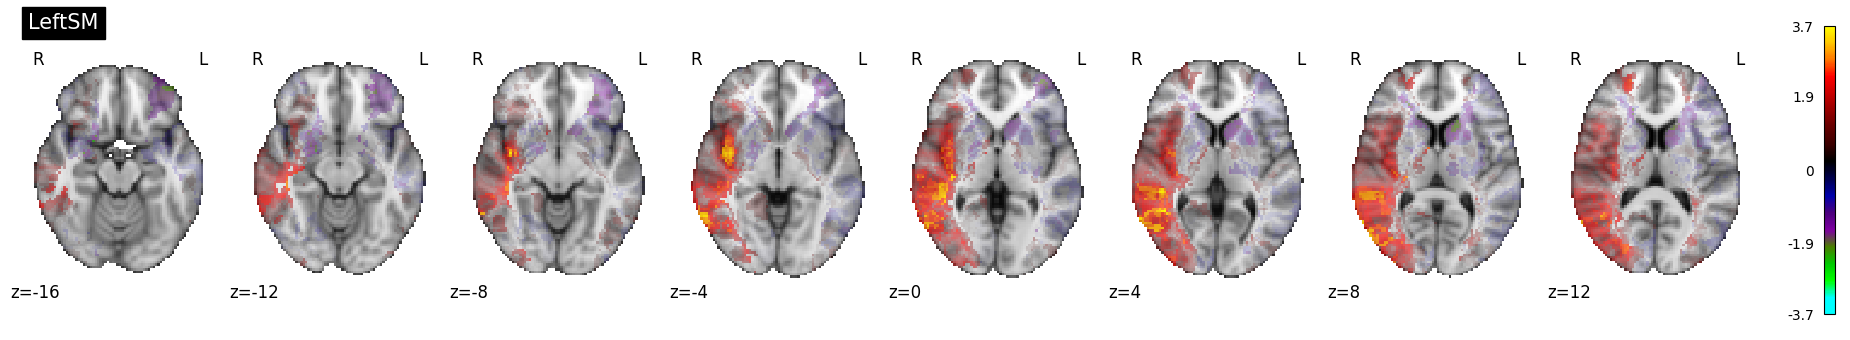

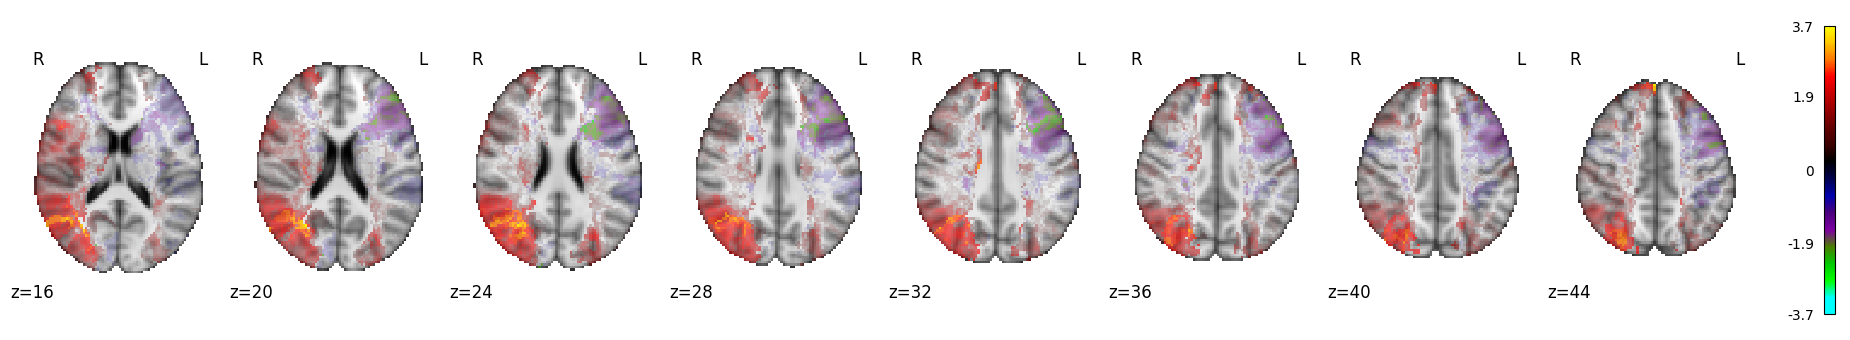

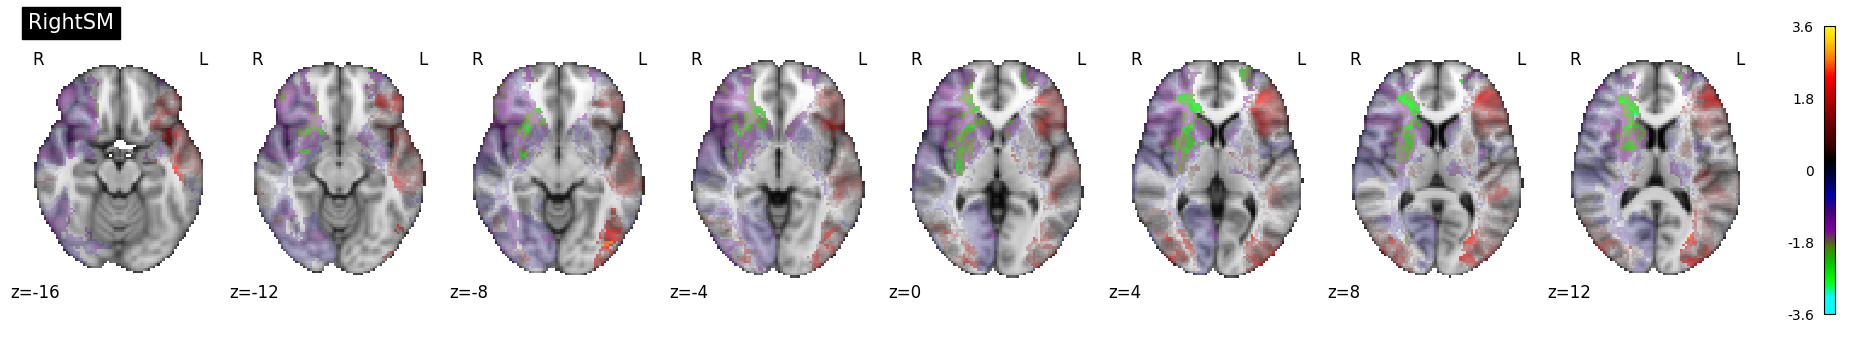

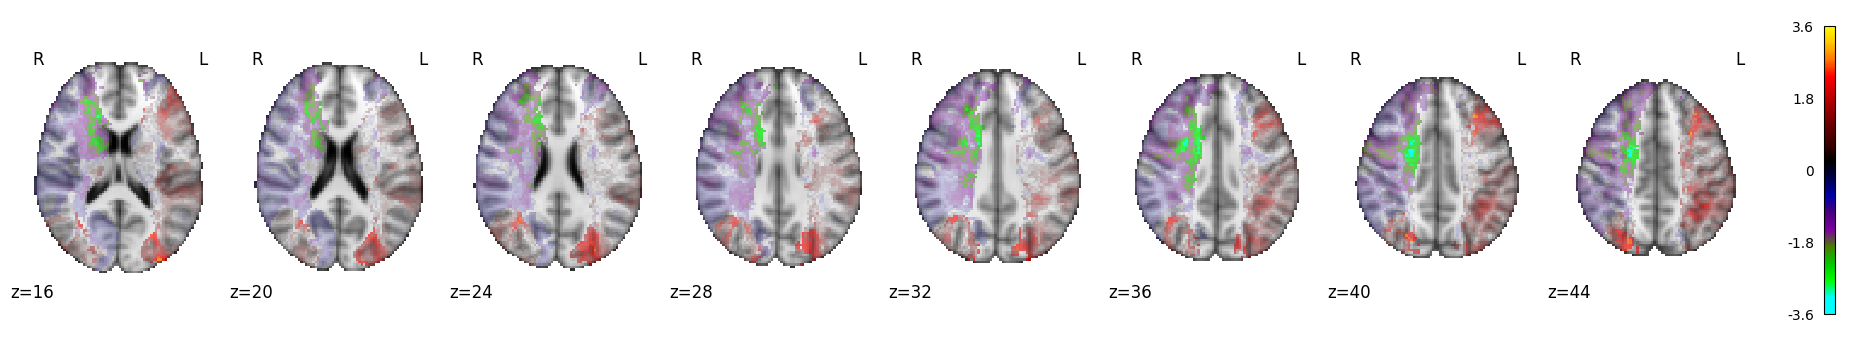

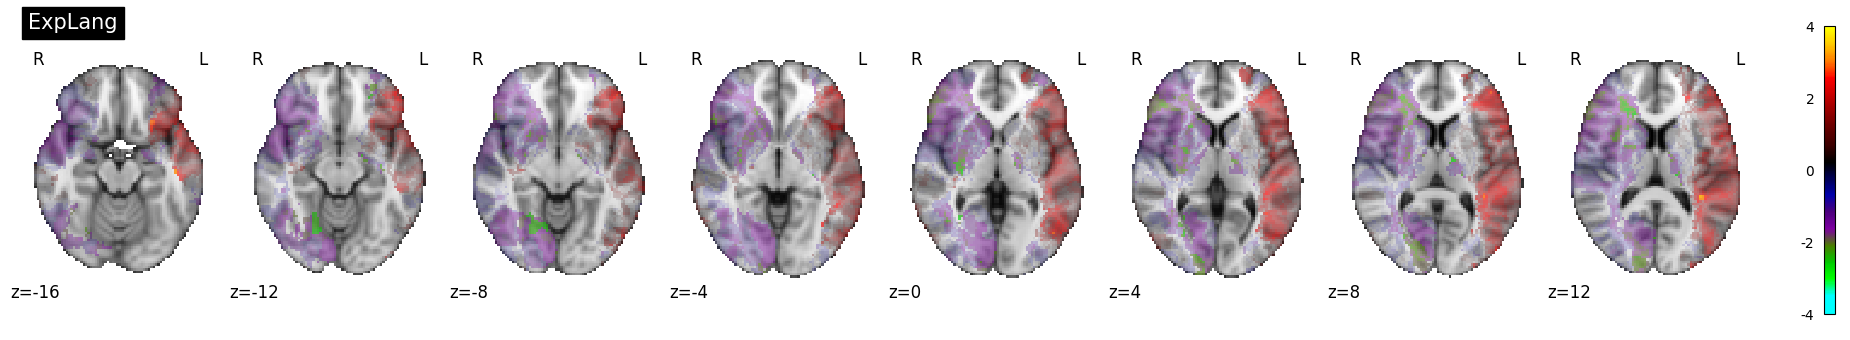

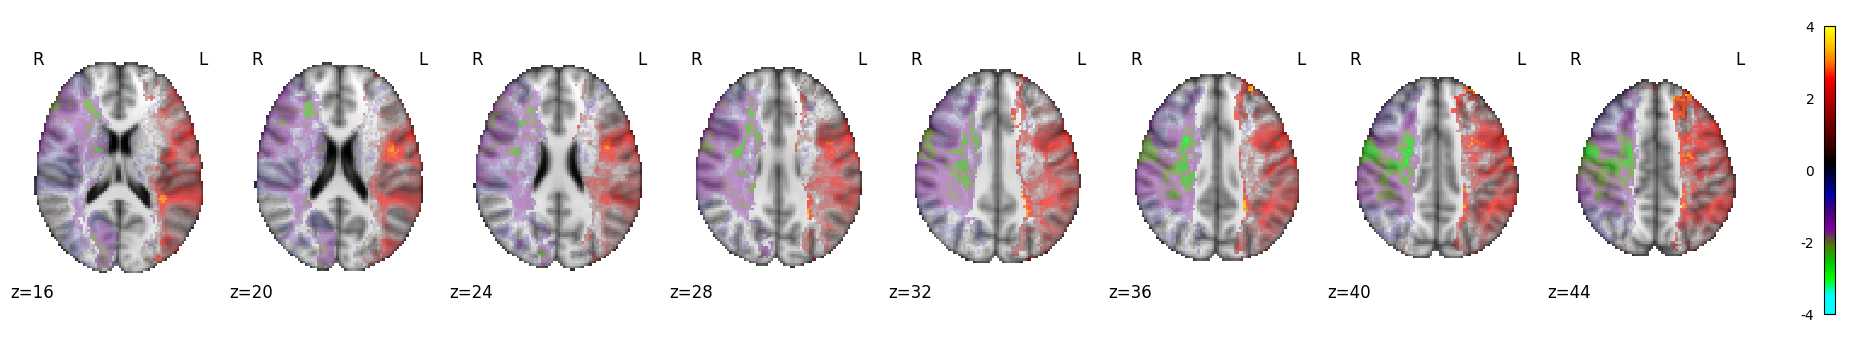

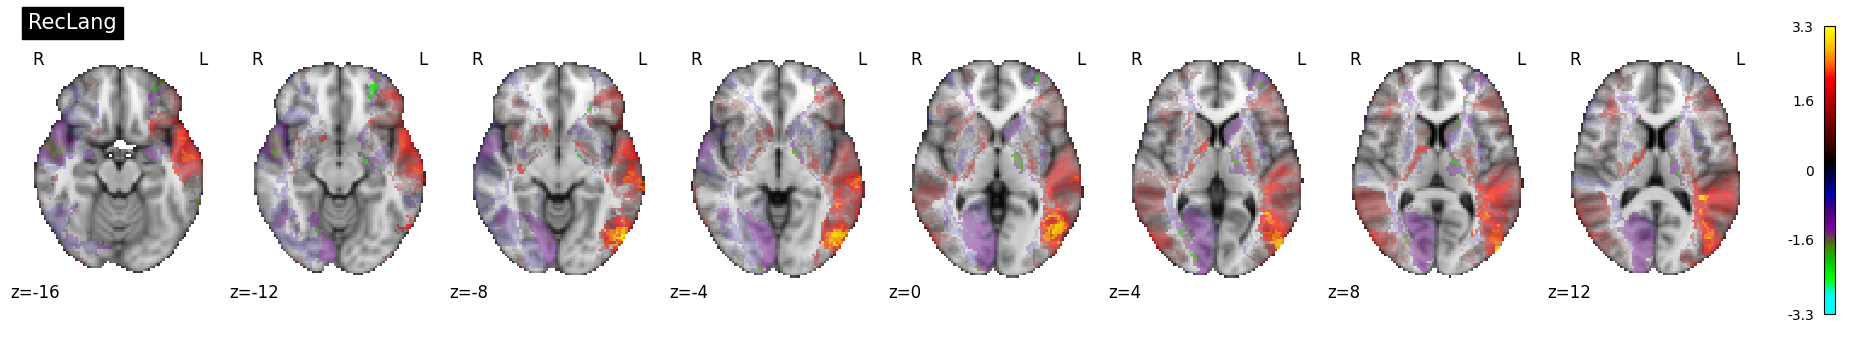

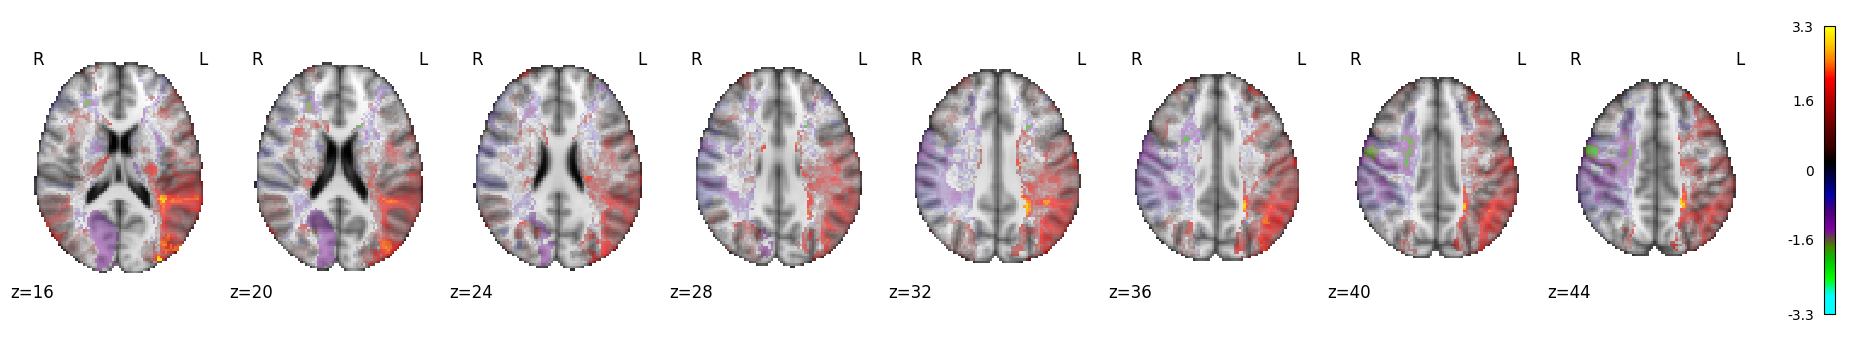

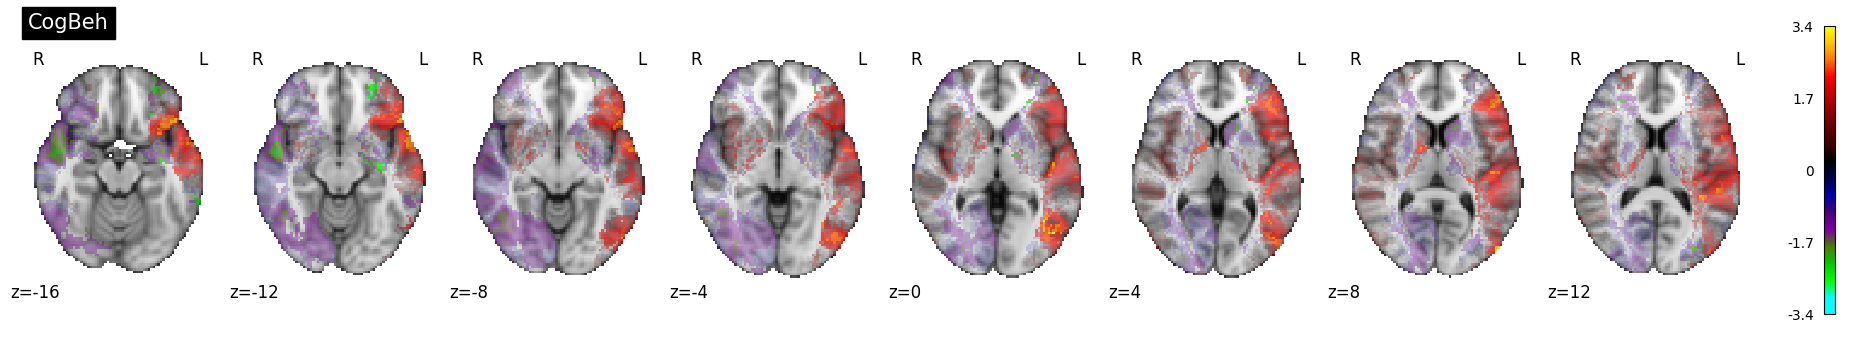

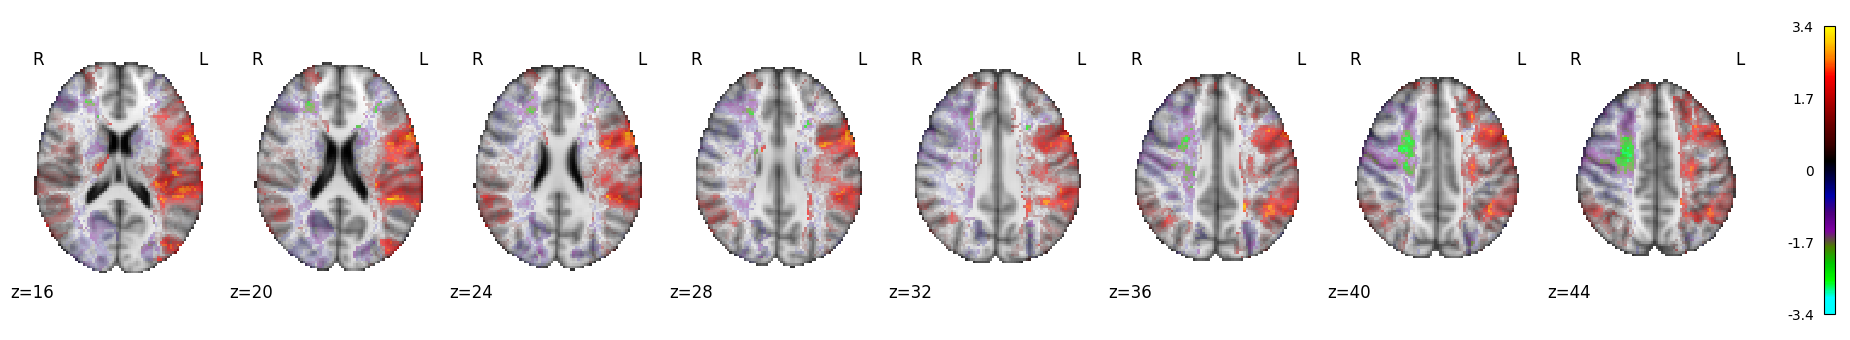

In [12]:
import nibabel as nib 
import numpy as np 
import pandas as pd
import os 
from nilearn import image
from nilearn.plotting import plot_stat_map, plot_glass_brain, plot_img

# Data directory
data_dir = '/home/jcgriffis/LSS/boeslab/Users/jcgriffis/vips_psom_mapping/results_moderation_71626/minstrokeage0_mintest0_no_exc'

# Outcome list
my_outcomes = [ "Left", "Right", "Verbal", "LanguageReception", "Cognitive_Behavioral"]
names = ["LeftSM", "RightSM", "ExpLang", "RecLang", "CogBeh"]

for i, outcome in enumerate(my_outcomes):
    
    # Model
    model = "lesion" # slnm_ldbs, flnm
    
    # Result folder
    result_dir = os.path.join(data_dir, outcome, 'munimnr_' + model)
    
    # Load image
    my_img = nib.load(os.path.join(result_dir, 'tstat_map_raw.nii'))
    img_data = my_img.get_fdata()
    max_val = np.max(np.abs(img_data[:]))
    my_img = nib.Nifti1Image(img_data, my_img.affine)  
    
    # Load background
    bg_img = nib.load('/home/jcgriffis/LSS/boeslab/Atlas/volumetric/MNI152/2mm/MNI152_T1_2mm.nii.gz')
    img_data = bg_img.get_fdata()
    mask_img = nib.load('/home/jcgriffis/LSS/boeslab/Atlas/volumetric/MNI152/2mm/masks/wholecb_mask.nii.gz')
    mask_data = mask_img.get_fdata()
    img_data[np.isnan(img_data)==True] = 0
    img_data[mask_data == 0] = 0
    bg_img = nib.Nifti1Image(img_data, bg_img.affine)
    
    # Plot image
    my_cmap = "roy_big_bl"
    p1 = plot_img(my_img, bg_img=bg_img, cmap=my_cmap, colorbar=True, transparency=my_img, transparency_range=[0.01, max_val], vmin=-1*max_val, vmax=max_val,  display_mode='z', cut_coords=list(range(-16,16,4)), resampling_interpolation='nearest', radiological=True, black_bg=False, title=names[i])            
    p1 = plot_img(my_img, bg_img=bg_img, cmap=my_cmap, colorbar=True, transparency=my_img, transparency_range=[0.01, max_val], vmin=-1*max_val, vmax=max_val, display_mode='z', cut_coords=list(range(16,46,4)), resampling_interpolation='nearest', radiological=True, black_bg=False)        